/home/ruirodrigues/Documents/Visão /venv/lib/python3.12/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


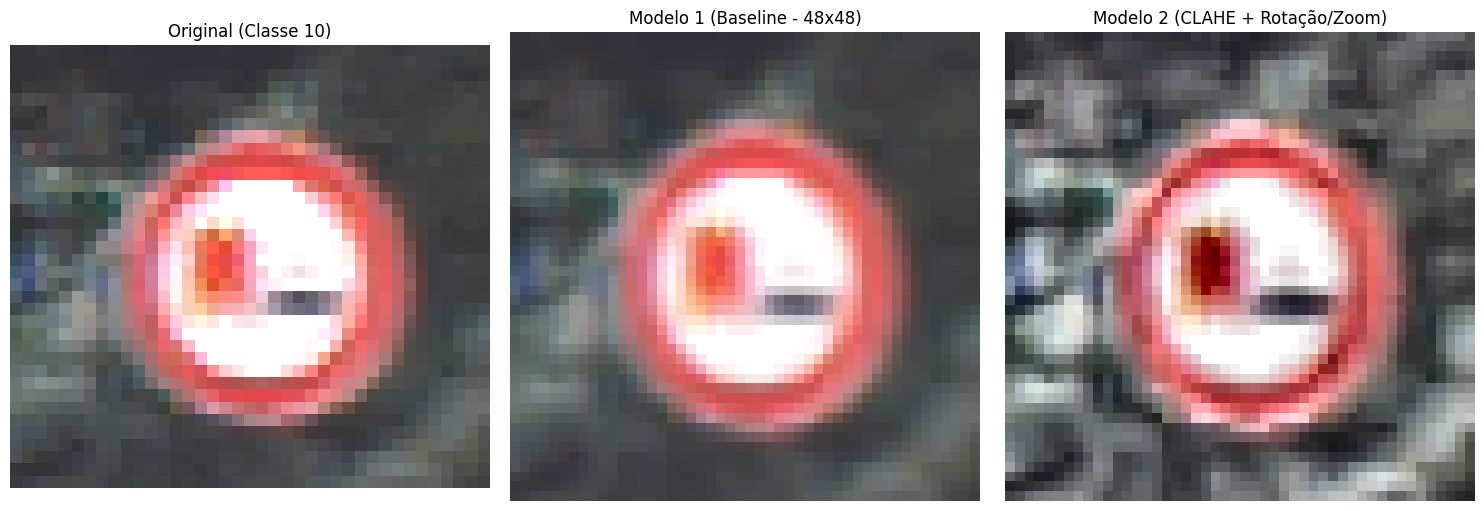

In [ ]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

sys.path.append(os.path.abspath('..'))
from src.dataset import get_data_splits, GTSRBDataset
from src.augmentation import get_train_transform_baseline, get_train_transform_geo

# ==========================================
# = Carregar as Pipelines de Augmentation  =
# ==========================================

TRAIN_DIR = "../data/GTSRB/Training"
train_df, _ = get_data_splits(TRAIN_DIR)

# Criei três versões do Dataset para a mesma lista de imagens
dataset_original = GTSRBDataset(train_df, transform=None) 
dataset_baseline = GTSRBDataset(train_df, transform=get_train_transform_baseline())
dataset_geo = GTSRBDataset(train_df, transform=get_train_transform_geo())

# Valores de normalização (precisamos deles para "desnormalizar" e mostrar a imagem)
GTSRB_MEAN = [0.3403, 0.3121, 0.3214]
GTSRB_STD = [0.2724, 0.2608, 0.2669]

def unnormalize(img_tensor):
    """Reverte a normalização do PyTorch para conseguirmos ver a imagem no ecrã"""
    img = img_tensor.clone().numpy().transpose(1, 2, 0)
    img = img * GTSRB_STD + GTSRB_MEAN
    img = np.clip(img, 0, 1)
    return img

# ==========================================
# =  Visualização das imagens lado a lado  =
# ==========================================

# Escolhe uma imagem aleatória (muda o índice para veres sinais diferentes)
idx = 150 
img_orig, label = dataset_original[idx]
img_base, _ = dataset_baseline[idx]
img_geo, _ = dataset_geo[idx]

plt.figure(figsize=(15, 5))

# 1- Imagem Original (Tamanho e cor originais)
plt.subplot(1, 3, 1)
plt.imshow(img_orig)
plt.title(f"Original (Classe {label})")
plt.axis('off')

# 2- Baseline (Redimensionada para 48x48, sem filtros)
plt.subplot(1, 3, 2)
plt.imshow(unnormalize(img_base))
plt.title("Modelo 1 (Baseline - 48x48)")
plt.axis('off')

# 3- Geo + CLAHE (Onde se vê a equalização de luz e distorção geométrica)
plt.subplot(1, 3, 3)
plt.imshow(unnormalize(img_geo))
plt.title("Modelo 2 (CLAHE + Rotação/Zoom)")
plt.axis('off')

plt.tight_layout()
plt.show()